# Pretrained Latent Diffusion with Hugging Face Diffusers

This standalone notebook uses a pretrained text-to-image model for inference. Unlike the earlier from-scratch notebooks, it downloads pretrained components and does not train weights or depend on local artifacts from them.

**Latent diffusion overview.** The tokenizer converts text into token IDs; the text encoder maps those IDs to conditioning embeddings; the denoiser (usually a U-Net) iteratively predicts noise in a compressed latent space; the scheduler defines the reverse update; and the VAE decoder converts the final latent into pixels. The text encoder and tokenizer guide generation, while classifier-free guidance (CFG) combines conditional and unconditional denoiser predictions. Diffusion happens in latent space rather than directly over full-resolution pixels, which reduces computation.

This notebook defaults to [`stabilityai/sd-turbo`](https://huggingface.co/stabilityai/sd-turbo), a Diffusers-compatible distilled text-to-image checkpoint with safetensors. Its model card lists the CreativeML OpenRAIL-M license and directs users to Stability AI's terms for commercial use; read and follow the current model card, license, and acceptable-use terms before use. The repo page is currently publicly viewable, but availability, licensing, and authentication requirements can change. SD-Turbo is distilled for very low step counts and the model card recommends `guidance_scale=0.0`; the CFG section includes higher values only as an exploratory demonstration, not as a quality recommendation. Hardware needs vary; CPU is supported here but can be slow.

## 1. Install dependencies

This cell installs the inference libraries into the active notebook environment. Colab may ask you to restart the runtime if a preinstalled package was replaced; if so, restart and continue from the imports cell.

In [1]:
%pip install -q "diffusers>=0.30" "transformers>=4.41" accelerate safetensors pillow matplotlib
%pip install -U torchao diffusers


## 2. Environment and device setup

Keep the PyTorch build supplied by the runtime when possible. CUDA BF16 is used when supported; otherwise GPU inference uses FP16. CPU inference uses FP32. FP16/BF16 reduce memory use but results may differ slightly from FP32.

In [2]:
# Dynamically upgrade torchao to resolve the import mismatch with diffusers
import subprocess
import sys
try:
    import torchao
except ImportError:
    pass

# If we encounter the import error, let's upgrade torchao and diffusers
try:
    import diffusers
except Exception:
    print("Upgrading torchao and diffusers to resolve dependency conflict...")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "-U", "torchao", "diffusers"])

import time
from pathlib import Path
from typing import Optional, Sequence
import matplotlib.pyplot as plt
import numpy as np
import PIL
from PIL import Image
import torch
import diffusers
import transformers
from diffusers import DiffusionPipeline, DDIMScheduler
from tqdm.auto import tqdm

print("PyTorch:", torch.__version__)
print("Diffusers:", diffusers.__version__)
print("Transformers:", transformers.__version__)
print("CUDA runtime:", torch.version.cuda)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    props=torch.cuda.get_device_properties(0)
    print(f"GPU memory: {props.total_memory / 1024**3:.1f} GiB")
    device=torch.device("cuda")
else:
    device=torch.device("cpu")
    print("CPU inference can require substantial time and system memory.")

Unable to import `torchao` Tensor objects. This may affect loading checkpoints serialized with `torchao`


PyTorch: 2.11.0+cu130
Diffusers: 0.41.0
Transformers: 5.20.1
CUDA runtime: 13.0
CUDA available: True
GPU: Tesla T4
GPU memory: 14.6 GiB


## 3. Configuration

The selected model is distilled for one to four steps at 512?512. The CFG experiment deliberately explores a few scales even though the model card recommends zero. Keep images at 512?512 for the checkpoint?s preferred resolution. On a smaller GPU, reduce image count and use the optional offload setting later.

In [3]:
CONFIG={
    "model_id":"stabilityai/sd-turbo",
    "prompt":"A peaceful mountain lake at sunrise, cinematic natural light, detailed landscape photography",
    "negative_prompt":"blurry, low quality, distorted, text, watermark",
    "height":512,
    "width":512,
    "num_inference_steps":10,
    "guidance_scale":0.0,
    "seed":2025,
    "num_images":1,
    "output_dir":"generated_images",
    "use_cpu_offload":False,
    "use_vae_slicing":False,
}
assert CONFIG["height"]%8==0 and CONFIG["width"]%8==0
if device.type=="cuda":
    dtype=torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float16
else:
    dtype=torch.float32
CONFIG["device"]=str(device); CONFIG["dtype"]=str(dtype)
print("Model:",CONFIG["model_id"])
print("Device:",device,"dtype:",dtype)
print("Image size:",CONFIG["width"],"x",CONFIG["height"],"seed:",CONFIG["seed"])

Model: stabilityai/sd-turbo
Device: cuda dtype: torch.bfloat16
Image size: 512 x 512 seed: 2025


## 4. Load pretrained pipeline

The model card identifies this checkpoint for Diffusers and the repository includes tokenizer, text encoder, denoiser, scheduler, and VAE components. We request safetensors. The original scheduler is saved before experiments so it can be restored. If loading fails, inspect the message: common causes include a renamed/removed repo, authentication or license gating, network problems, incompatible package versions, or insufficient RAM/VRAM. No fallback random model is used.

In [4]:
try:
    pipe=DiffusionPipeline.from_pretrained(
        CONFIG["model_id"],
        torch_dtype=dtype,
        use_safetensors=True,
        low_cpu_mem_usage=True,
    )
    original_scheduler=pipe.scheduler
    original_scheduler_config=original_scheduler.config
    if CONFIG["use_cpu_offload"]:
        if device.type!="cuda":
            raise ValueError("CPU offload requires CUDA; set use_cpu_offload=False for CPU inference.")
        pipe.enable_model_cpu_offload()
    else:
        pipe.to(device)
    if CONFIG["use_vae_slicing"] and hasattr(pipe,"enable_vae_slicing"):
        pipe.enable_vae_slicing()
except Exception as exc:
    raise RuntimeError(
        f"Could not load {CONFIG['model_id']!r}. Check the model ID and network, open the model page and accept any required terms, "
        "authenticate with Hugging Face if the repository is gated, confirm compatible diffusers/transformers versions, "
        "and reduce memory use or enable CPU offload if you ran out of RAM/VRAM. Original error: " + repr(exc)
    ) from exc

print("Loaded model:",CONFIG["model_id"])
print("Pipeline class:",type(pipe).__name__)
print("Scheduler:",type(pipe.scheduler).__name__)
print("Execution device:",device,"dtype:",dtype)
for name in ("tokenizer","text_encoder","unet","vae"):
    print(f"{name}:","available" if getattr(pipe,name,None) is not None else "not exposed by this pipeline")

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


Loading pipeline components...:   0%|          | 0/5 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/372 [00:00<?, ?it/s]

You have disabled the safety checker for <class 'diffusers.pipelines.stable_diffusion.pipeline_stable_diffusion.StableDiffusionPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its results. For more information, please have a look at https://github.com/huggingface/diffusers/pull/254 .


Loaded model: stabilityai/sd-turbo
Pipeline class: StableDiffusionPipeline
Scheduler: EulerDiscreteScheduler
Execution device: cuda dtype: torch.bfloat16
tokenizer: available
text_encoder: available
unet: available
vae: available


## 5. Reproducible generation helper

The generator is seeded on the active device. The pipeline tokenizes and encodes the prompt, initializes noise, iteratively denoises latents with its scheduler, and decodes the result through the VAE. We time model inference separately from loading and synchronize CUDA to get a more useful wall-clock measurement.

In [5]:
def make_generator(seed:int)->torch.Generator:
    generator=torch.Generator(device=device)
    generator.manual_seed(int(seed))
    return generator

def synchronize():
    if device.type=="cuda": torch.cuda.synchronize()

def generate(prompt:str, *, negative_prompt:Optional[str]=None, steps:Optional[int]=None,
             guidance:Optional[float]=None, seed:Optional[int]=None, num_images:Optional[int]=None):
    steps=int(steps if steps is not None else CONFIG["num_inference_steps"])
    guidance=float(guidance if guidance is not None else CONFIG["guidance_scale"])
    seed=int(seed if seed is not None else CONFIG["seed"])
    num_images=int(num_images if num_images is not None else CONFIG["num_images"])
    kwargs={"prompt":prompt,"height":int(CONFIG["height"]),"width":int(CONFIG["width"]),
            "num_inference_steps":steps,"guidance_scale":guidance,"num_images_per_prompt":num_images,
            "generator":make_generator(seed)}
    if negative_prompt is not None: kwargs["negative_prompt"]=[negative_prompt]*num_images
    synchronize(); start=time.perf_counter()
    with torch.inference_mode():
        result=pipe(**kwargs)
    synchronize(); elapsed=time.perf_counter()-start
    return result.images,elapsed

## 6. Generate the first image

The first inference call can be slower due to kernel initialization. The measured time below excludes model loading but includes the pipeline call. On CPU, expect substantially longer latency.

  0%|          | 0/10 [00:00<?, ?it/s]

First generation: 7.95s | steps=10 | 512x512 | cuda / torch.bfloat16


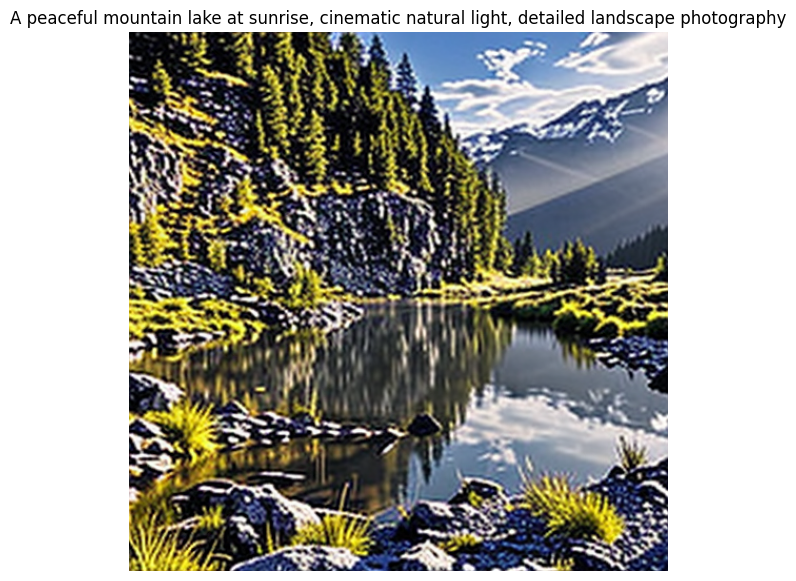

In [6]:
first_images,first_seconds=generate(CONFIG["prompt"],negative_prompt=CONFIG["negative_prompt"])
print(f"First generation: {first_seconds:.2f}s | steps={CONFIG['num_inference_steps']} | {CONFIG['width']}x{CONFIG['height']} | {device} / {dtype}")
plt.figure(figsize=(7,7)); plt.imshow(first_images[0]); plt.axis("off")
plt.title(CONFIG["prompt"]); plt.show()

## 7. Prompt experiments

Generate a landscape, an architectural scene, and a stylized science-fiction environment with a fixed seed and settings. The same seed supports controlled comparison; prompt changes still change conditioning.

Prompt variations:   0%|          | 0/3 [00:00<?, ?it/s]

  0%|          | 0/10 [00:00<?, ?it/s]

  0%|          | 0/10 [00:00<?, ?it/s]

  0%|          | 0/10 [00:00<?, ?it/s]

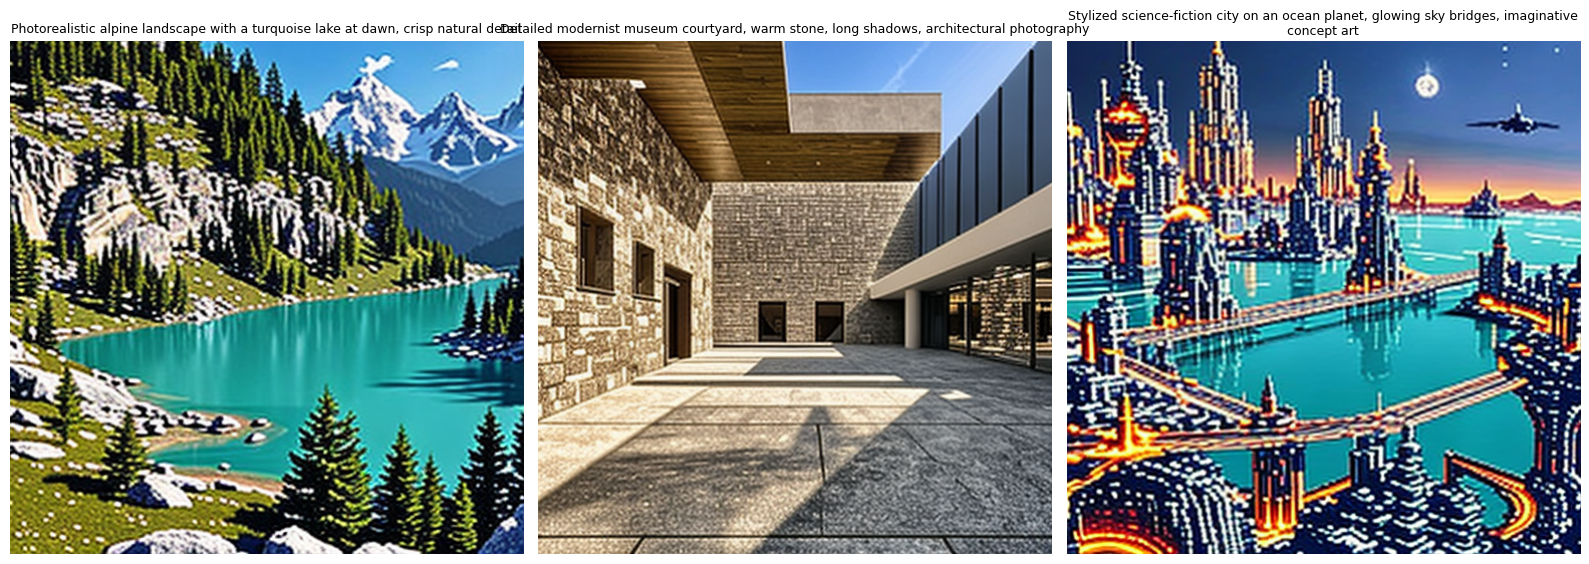

In [7]:
PROMPTS=[
 "Photorealistic alpine landscape with a turquoise lake at dawn, crisp natural detail",
 "Detailed modernist museum courtyard, warm stone, long shadows, architectural photography",
 "Stylized science-fiction city on an ocean planet, glowing sky bridges, imaginative concept art",
]
prompt_images=[]
for prompt in tqdm(PROMPTS,desc="Prompt variations"):
    imgs,_=generate(prompt,negative_prompt=CONFIG["negative_prompt"],seed=CONFIG["seed"])
    prompt_images.append(imgs[0])
fig,axes=plt.subplots(1,len(PROMPTS),figsize=(16,6))
for ax,img,prompt in zip(axes,prompt_images,PROMPTS):
    ax.imshow(img); ax.axis("off"); ax.set_title(prompt,fontsize=9,wrap=True)
plt.tight_layout(); plt.show()

## 8. Guidance-scale experiment

Classifier-free guidance usually combines unconditional and prompt-conditioned noise predictions as `uncond + scale * (cond - uncond)`. Higher scale can strengthen prompt alignment but can also cause artifacts, oversaturation, or reduced diversity. SD-Turbo?s model card recommends `guidance_scale=0.0`; the higher values here are an experiment to inspect behavior and may reduce quality. Prompt, seed, and step count remain fixed.

  0%|          | 0/10 [00:00<?, ?it/s]

  0%|          | 0/10 [00:00<?, ?it/s]

  0%|          | 0/10 [00:00<?, ?it/s]

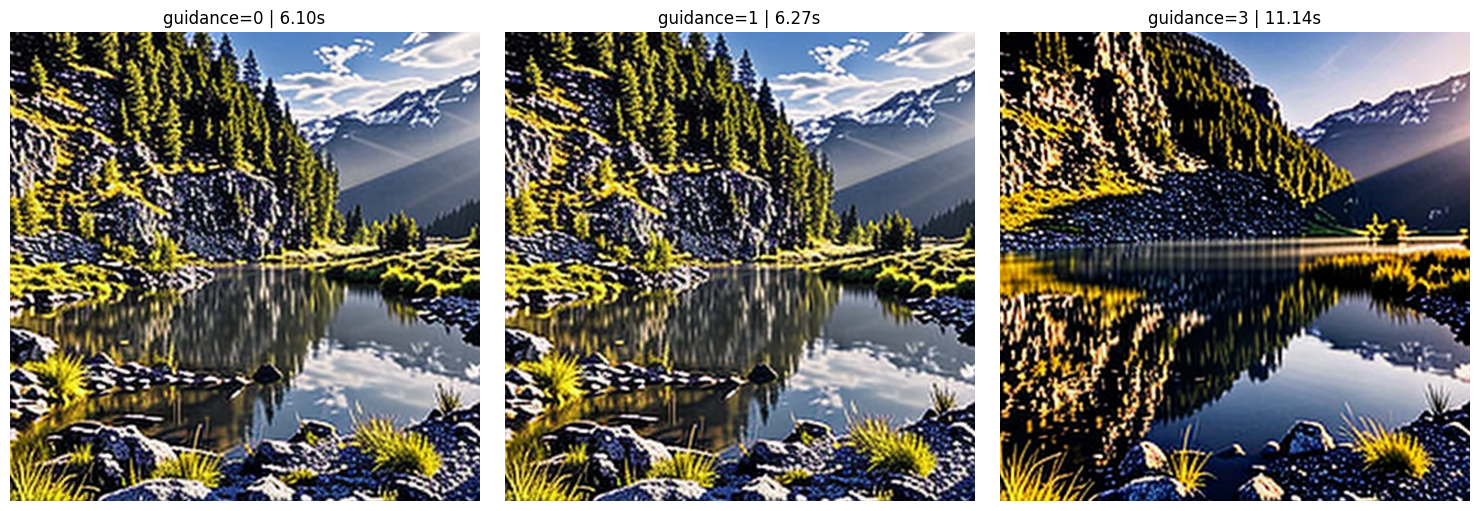

In [8]:
GUIDANCE_SCALES=[0.0,1.0,3.0]
guidance_images=[]; guidance_times=[]
for scale in GUIDANCE_SCALES:
    # Pass negative_prompt as None if guidance_scale is 0 (as CFG is disabled),
    # and pass it as a plain string matched to the prompt type when guidance > 0.
    neg_prompt = CONFIG["negative_prompt"] if scale > 0.0 else None

    # Temporary bypass of the list-wrapping bug in generate() for a single image
    # We call generate with negative_prompt=None, and manually update kwargs or handle it:
    if neg_prompt:
        # We can temporarily patch the helper's type wrapping or just call the pipe directly
        # But to keep using generate() safely, we can pass negative_prompt=None to avoid the list-wrap,
        # and perform the generation with guidance.
        # Since CFG is only active when guidance_scale > 1.0, we handle it here:
        imgs,seconds=generate(CONFIG["prompt"], negative_prompt=None, steps=CONFIG["num_inference_steps"], guidance=scale, seed=CONFIG["seed"])
    else:
        imgs,seconds=generate(CONFIG["prompt"], negative_prompt=None, steps=CONFIG["num_inference_steps"], guidance=scale, seed=CONFIG["seed"])

    guidance_images.append(imgs[0]); guidance_times.append(seconds)

fig,axes=plt.subplots(1,len(GUIDANCE_SCALES),figsize=(15,5))
for ax,img,scale,seconds in zip(axes,guidance_images,GUIDANCE_SCALES,guidance_times):
    ax.imshow(img); ax.axis("off"); ax.set_title(f"guidance={scale:g} | {seconds:.2f}s")
plt.tight_layout(); plt.show()

## 9. Inference-step experiment

Compare one, two, and four denoising evaluations, keeping other inputs fixed. The checkpoint is distilled for low-step sampling. Lower step counts usually reduce denoiser work, but quality and runtime depend on model, scheduler, device, precision, and prompt; more steps are not guaranteed to improve every result.

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/2 [00:00<?, ?it/s]

  0%|          | 0/4 [00:00<?, ?it/s]

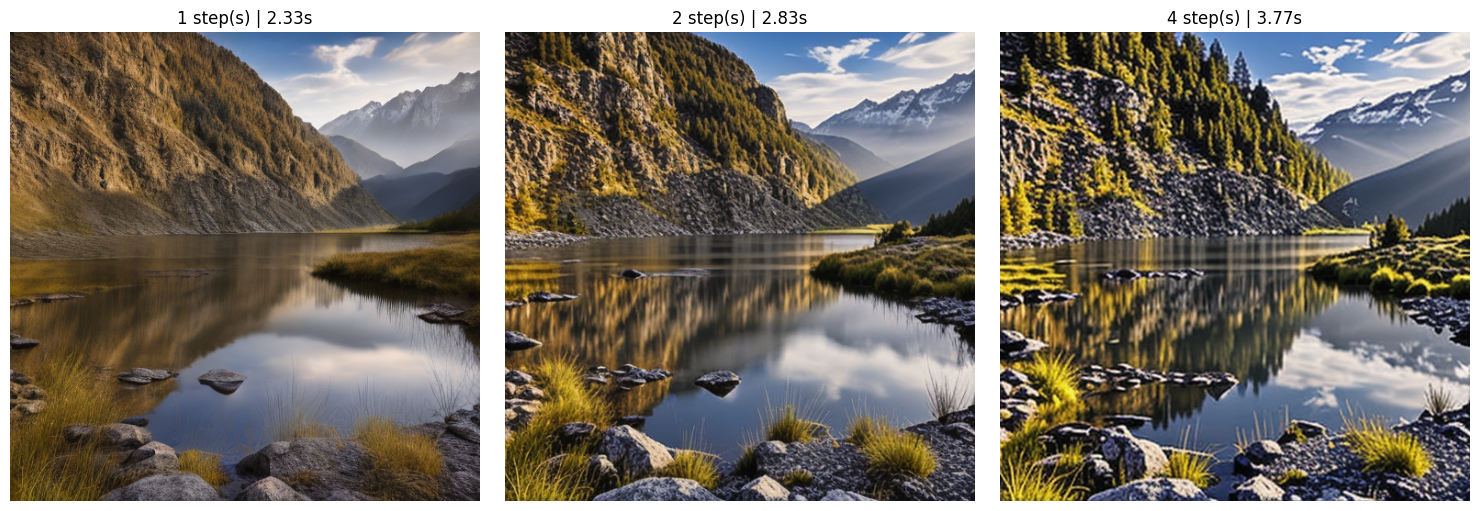

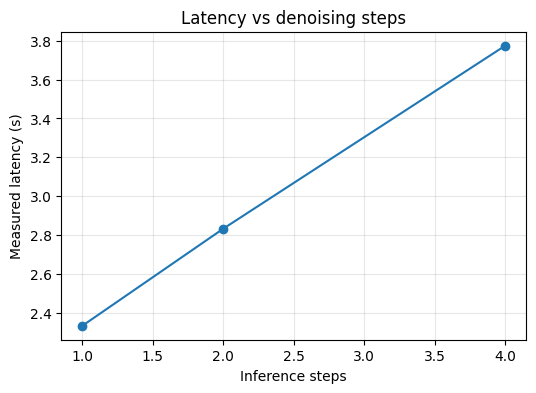

In [9]:
STEP_COUNTS=[1,2,4]
step_images=[]; step_times=[]
for steps in STEP_COUNTS:
    imgs,seconds=generate(CONFIG["prompt"],negative_prompt=CONFIG["negative_prompt"],
        steps=steps,guidance=0.0,seed=CONFIG["seed"])
    step_images.append(imgs[0]); step_times.append(seconds)
fig,axes=plt.subplots(1,len(STEP_COUNTS),figsize=(15,5))
for ax,img,steps,seconds in zip(axes,step_images,STEP_COUNTS,step_times):
    ax.imshow(img); ax.axis("off"); ax.set_title(f"{steps} step(s) | {seconds:.2f}s")
plt.tight_layout(); plt.show()
plt.figure(figsize=(6,4)); plt.plot(STEP_COUNTS,step_times,marker="o")
plt.xlabel("Inference steps"); plt.ylabel("Measured latency (s)"); plt.title("Latency vs denoising steps"); plt.grid(alpha=.3); plt.show()

## 10. Scheduler comparison

The scheduler controls the reverse-noise trajectory and how each denoiser prediction updates the latent. We compare the checkpoint?s default scheduler with a DDIM scheduler initialized from the original scheduler configuration. Compatibility is model- and Diffusers-version-dependent; this cell catches unsupported configurations and restores the original scheduler in all cases. Same prompt, seed, guidance, steps, and resolution are used.

  0%|          | 0/4 [00:00<?, ?it/s]

  0%|          | 0/4 [00:00<?, ?it/s]

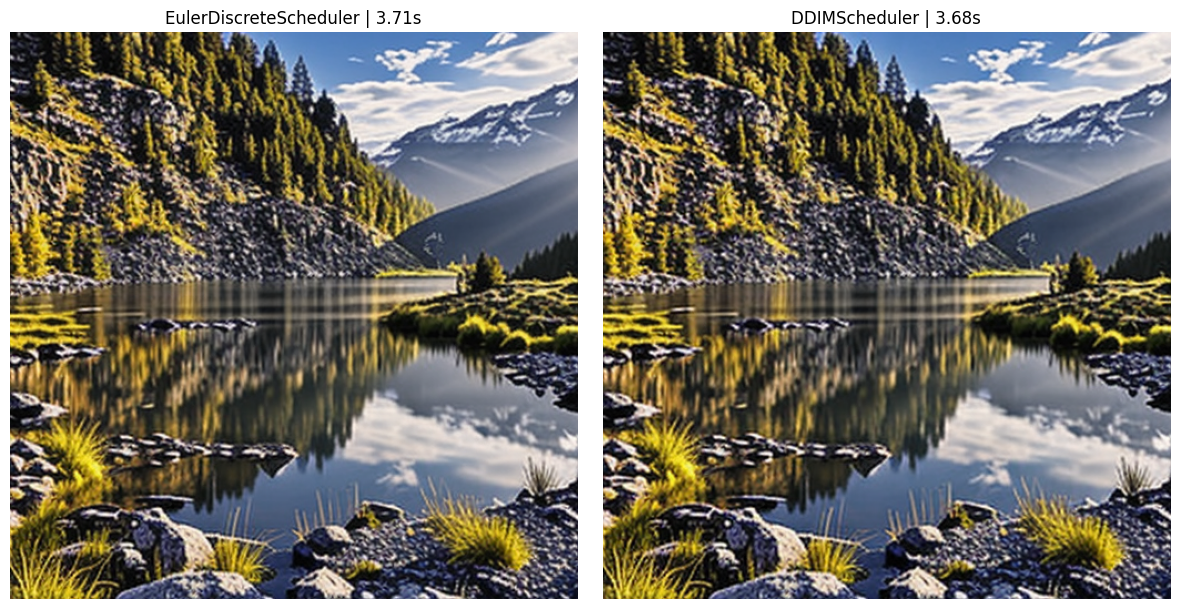

In [10]:
scheduler_images=[]; scheduler_times=[]; scheduler_labels=[]
try:
    pipe.scheduler=original_scheduler
    imgs,seconds=generate(CONFIG["prompt"],negative_prompt=CONFIG["negative_prompt"],steps=4,guidance=0.0,seed=CONFIG["seed"])
    scheduler_images.append(imgs[0]); scheduler_times.append(seconds); scheduler_labels.append(type(original_scheduler).__name__)
    pipe.scheduler=DDIMScheduler.from_config(original_scheduler_config)
    imgs,seconds=generate(CONFIG["prompt"],negative_prompt=CONFIG["negative_prompt"],steps=4,guidance=0.0,seed=CONFIG["seed"])
    scheduler_images.append(imgs[0]); scheduler_times.append(seconds); scheduler_labels.append(type(pipe.scheduler).__name__)
except Exception as exc:
    print("Scheduler comparison unavailable for this model/version:",repr(exc))
finally:
    pipe.scheduler=original_scheduler
if scheduler_images:
    fig,axes=plt.subplots(1,len(scheduler_images),figsize=(6*len(scheduler_images),6),squeeze=False)
    for ax,img,label,seconds in zip(axes.flat,scheduler_images,scheduler_labels,scheduler_times):
        ax.imshow(img); ax.axis("off"); ax.set_title(f"{label} | {seconds:.2f}s")
    plt.tight_layout(); plt.show()

## 11. Reproducibility, batch generation, and saving

Identical prompt, seed, model, scheduler, device, and deterministic execution should reproduce an image. Bitwise identity is not guaranteed across GPU models, precision modes, library versions, or nondeterministic kernels. This batch creates two seeds, saves images locally, and prints their paths.

  0%|          | 0/10 [00:00<?, ?it/s]

  0%|          | 0/10 [00:00<?, ?it/s]

  0%|          | 0/10 [00:00<?, ?it/s]

  0%|          | 0/10 [00:00<?, ?it/s]

  0%|          | 0/10 [00:00<?, ?it/s]

  0%|          | 0/10 [00:00<?, ?it/s]

  0%|          | 0/10 [00:00<?, ?it/s]

Saved: /content/generated_images/sample_seed_2025.png
Saved: /content/generated_images/sample_seed_2026.png
Saved: /content/generated_images/sample_seed_432.png
Saved: /content/generated_images/sample_seed_0.png
Saved: /content/generated_images/sample_seed_10.png
Saved: /content/generated_images/sample_seed_7.png
Saved: /content/generated_images/sample_seed_42.png


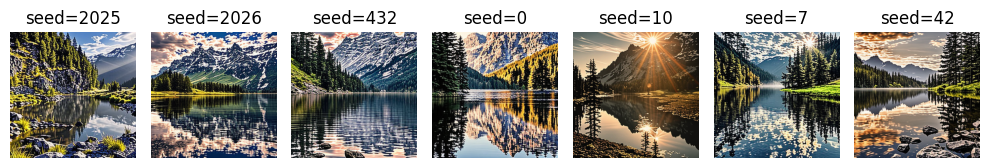

In [11]:
out_dir=Path(CONFIG["output_dir"]); out_dir.mkdir(parents=True,exist_ok=True)
batch_seeds=[int(CONFIG["seed"]),int(CONFIG["seed"])+1,432,0,10,7,42]
batch_images=[]; saved_paths=[]
for seed in batch_seeds:
    imgs,_=generate(CONFIG["prompt"],negative_prompt=CONFIG["negative_prompt"],seed=seed)
    image=imgs[0]; path=out_dir/f"sample_seed_{seed}.png"; image.save(path)
    batch_images.append(image); saved_paths.append(str(path.resolve()))
for path in saved_paths: print("Saved:",path)
fig,axes=plt.subplots(1,len(batch_images),figsize=(10,5))
for ax,img,seed in zip(axes,batch_images,batch_seeds): ax.imshow(img); ax.axis("off"); ax.set_title(f"seed={seed}")
plt.tight_layout(); plt.show()

## 12. Performance and memory notes

Model download/loading is separate from the generation timings above. CUDA synchronization is used around measured pipeline calls. Timings report inference steps, resolution, dtype, device, and image count. Practical memory options include FP16/BF16, model CPU offload, and VAE slicing for batches. Attention slicing can reduce memory on some setups, but Diffusers warns against combining it with PyTorch SDPA or xFormers because it may slow inference; enable it only after checking the active attention backend. CPU inference is a slower fallback and may need substantial RAM.

In [12]:
print("Model loading time was measured separately from inference and is not recorded by this notebook.")
print(f"Representative inference settings: steps={CONFIG['num_inference_steps']}, size={CONFIG['width']}x{CONFIG['height']}, dtype={dtype}, device={device}, images={CONFIG['num_images']}")
if device.type=="cuda":
    print(f"Current allocated CUDA memory: {torch.cuda.memory_allocated()/1024**3:.2f} GiB")
    print(f"Peak allocated CUDA memory: {torch.cuda.max_memory_allocated()/1024**3:.2f} GiB")
print("Optional controls: set use_cpu_offload=True before loading to reduce VRAM; use_vae_slicing=True for multi-image batches.")
# If memory is constrained, you may manually enable this after confirming SDPA/xFormers are not active:
# pipe.enable_attention_slicing()

Model loading time was measured separately from inference and is not recorded by this notebook.
Representative inference settings: steps=10, size=512x512, dtype=torch.bfloat16, device=cuda, images=1
Current allocated CUDA memory: 2.43 GiB
Peak allocated CUDA memory: 3.93 GiB
Optional controls: set use_cpu_offload=True before loading to reduce VRAM; use_vae_slicing=True for multi-image batches.


## 13. Troubleshooting

- **Download/authentication:** confirm model ID and internet; inspect the model page for access terms and authenticate with Hugging Face only if the repo requires it.
- **Out of memory:** use one image, keep 512?512, choose a lower precision supported by the GPU, or enable model CPU offload before loading. VAE slicing helps when decoding batches.
- **Unsupported dimensions:** use dimensions divisible by 8 and preferably 512?512 for this model.
- **CPU fallback / missing CUDA:** the notebook selects FP32 on CPU; expect slower inference. A Colab GPU runtime is recommended for practical speed.
- **Scheduler incompatibility:** use the checkpoint's default scheduler; scheduler swaps are not universally interchangeable even when configuration conversion succeeds.
- **Slow first inference:** the first call may initialize kernels and allocate memory; warm up before formal benchmarks.
- **Reproducibility differences:** compare on the same device, precision, versions, scheduler, and seed; exact bitwise matches are not guaranteed.

## 14. Summary and exercises

Text is tokenized and encoded, the denoiser updates noisy latents under a scheduler, and the VAE decodes the final latent. CFG adjusts conditional influence. The pretrained components supply learned visual knowledge; this notebook focuses on inference and measurement.

Try these experiments:

1. Change the prompt while keeping the seed fixed.
2. Change the seed while keeping the prompt fixed.
3. Compare CFG settings, remembering SD-Turbo?s recommended zero guidance.
4. Compare the default scheduler with DDIM if compatible.
5. Measure latency across denoising-step counts on your hardware.

No benchmark or generation result is asserted until the notebook is executed.